# 🔍 Explore the mapped data

**Goal:** Look at the data with our own eyes before loading it into MySQL.

## 📂 About the data

**Source:** NPCI UPI Ecosystem Statistics, "Top 50 Member Performance", Remitter tab. A remitter bank is the sender's bank, the one that approves or declines the payment.

**Period:** Aug *2024* to Jul *2026* (24 months)

**What one row is:** one bank in one month, with its payment attempts and how they ended.

**Size:** 1,198 rows. Each month lists the 50 biggest banks, so membership changes over time. NPCI publishes only the Top 50, so totals are not national UPI volume.

| Column | Meaning |
|---|---|
| `month` | The month of the data (first day of the month) |
| `bank_name` | Standard bank name, after our mapping |
| `volume_mn` | Payment attempts from this bank, in millions |
| `approved_pct` | % of attempts approved |
| `bd_pct` | % declined for business reasons (wrong PIN, low balance, limit crossed) |
| `td_pct` | % declined for technical reasons (system or network problems) |
| `is_ranked` | Added by us, not from NPCI. 1 = included in bank rankings, 0 = excluded (credit card entries, and Tri O Tech and One Mobikwik, which show no declines) |



**Left out:** NPCI's debit reversal columns, which are unreliable on small counts.

## Step 1: First look

**What:** Check the size, column types, missing values, and the first rows.

**Why:** Always start by seeing what you have.

**Expect:** `(1198, 7)` and 0 missing values.

**Look for:** What does one row represent?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files

files.upload()   # choose upi_remitter_mapped.csv
df = pd.read_csv('upi_remitter_mapped.csv', parse_dates=['month'])
print(df.shape)
print(df.dtypes)
print('missing values:', int(df.isna().sum().sum()))
df.head()

Saving upi_remitter_mapped.csv to upi_remitter_mapped.csv
(1198, 7)
month           datetime64[ns]
bank_name               object
volume_mn              float64
approved_pct           float64
bd_pct                 float64
td_pct                 float64
is_ranked                int64
dtype: object
missing values: 0


,month,bank_name,volume_mn,approved_pct,bd_pct,td_pct,is_ranked
0,2024-08-01,AU Small Finance Bank,69.40,91.26,8.72,0.02,1
1,2024-08-01,Airtel Payments Bank Limited,437.93,90.01,9.84,0.15,1
2,2024-08-01,Andhra Pradesh Grameena Vikas Bank,28.61,86.25,12.84,0.91,1
3,2024-08-01,Andhra Pragathi Grameena Bank,17.78,85.45,12.94,1.61,1
4,2024-08-01,Axis Bank Ltd.,730.47,95.47,4.53,0.00,1


## Step 2: Summary statistics

**What:** Count, average, min, max and quartiles for the four number columns.

**Why:** It shows the typical value and the extremes in one table.

**Look for:** Is volume's average much bigger than its median (the 50% row)? What are the smallest and biggest `td_pct`?

In [2]:
df[['volume_mn', 'approved_pct', 'bd_pct', 'td_pct']].describe().round(2)

,volume_mn,approved_pct,bd_pct,td_pct
count,1198.00,1198.00,1198.00,1198.00
mean,409.35,90.52,8.70,0.78
std,806.50,4.42,3.94,1.41
min,17.78,68.39,0.00,0.00
25%,45.69,88.49,6.35,0.10
50%,105.93,91.57,7.87,0.28
75%,483.53,93.10,10.62,0.80
max,6622.02,100.00,26.97,15.71


## Step 3: Who are the biggest banks?

**What:** Average monthly volume and average TD rate for the top 10 banks, and how much of all volume the top 5 handle.

**Why:** It shows whether volume is spread out or concentrated in a few banks.

**Look for:** Do the biggest banks also have the highest TD rates?

In [3]:
by_bank = df.groupby('bank_name').agg(
    months=('month', 'nunique'),
    avg_volume_mn=('volume_mn', 'mean'),
    avg_td_pct=('td_pct', 'mean')).round(2)

display(by_bank.sort_values('avg_volume_mn', ascending=False).head(10))

total = df.volume_mn.sum()
top5 = df.groupby('bank_name').volume_mn.sum().nlargest(5).sum()
print('Top 5 banks share of all volume:', round(top5 / total * 100, 1), '%')

,months,avg_volume_mn,avg_td_pct
bank_name,,,
State Bank of India,24,5250.70,0.50
HDFC Bank Ltd.,24,1525.85,0.04
Bank of Baroda,24,1351.72,0.13
Union Bank of India,24,1222.84,0.23
Punjab National Bank,24,1111.31,0.34
Kotak Mahindra Bank,24,973.60,0.10
Canara Bank,24,961.80,0.34
Axis Bank Ltd.,24,906.13,0.03
ICICI Bank Ltd.,24,724.78,0.09


Top 5 banks share of all volume: 51.2 %


## Step 4: How do the totals move over time?

**What:** Total volume and weighted TD for each month, as two line charts.

**Why:** It shows the overall trend before we look at any single bank.

**Look for:** Does volume grow steadily? Does weighted TD move the same way, or jump around?

,volume_mn,failed_mn,weighted_td_pct
month,,,
2024-08-01,15498.84,54.888,0.354
2024-09-01,15591.75,76.423,0.490
2024-10-01,17345.81,116.384,0.671


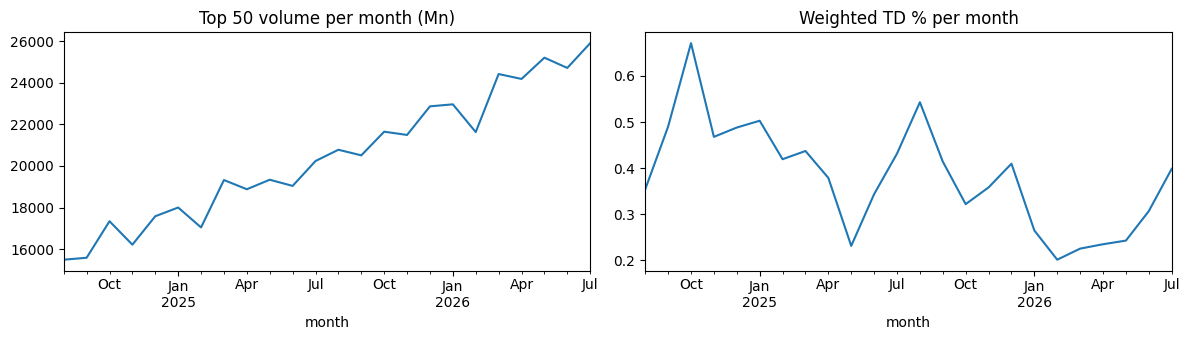

In [4]:
df['failed_mn'] = df.volume_mn * df.td_pct / 100
monthly = df.groupby('month').agg(volume_mn=('volume_mn', 'sum'), failed_mn=('failed_mn', 'sum'))
monthly['weighted_td_pct'] = monthly.failed_mn / monthly.volume_mn * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
monthly.volume_mn.plot(ax=ax[0], title='Top 50 volume per month (Mn)')
monthly.weighted_td_pct.plot(ax=ax[1], title='Weighted TD % per month')
plt.tight_layout()
monthly.round(3).head(3)

## Step 5: Spot the unusual values

**What:** A histogram of TD rates, a count of bank-months above 1%, and the 10 highest TD rates.

**Why:** Extreme values can be real problems or data issues. We need to know which before analysing.

**Look for:** Is the histogram bunched near zero with a long tail? What do the highest-TD banks have in common (size, month)? (The 1% line is only for exploring here, since the 1% benchmark is not confirmed.)


bank-months with TD above 1%: 254 of 1165


,month,bank_name,volume_mn,td_pct
332,2025-02-01,NSDL Payments Bank Limited,30.80,15.71
252,2025-01-01,Andhra Pragathi Grameena Bank,25.58,12.07
382,2025-03-01,NSDL Payments Bank Limited,34.89,11.58
103,2024-10-01,Andhra Pragathi Grameena Bank,21.92,11.34
203,2024-12-01,Andhra Pragathi Grameena Bank,26.11,11.16
658,2025-09-01,Baroda U.P. Bank,54.02,10.22
957,2026-03-01,Baroda U.P. Bank,90.10,10.17
28,2024-08-01,Karnataka Gramin Bank,30.19,7.83
609,2025-08-01,Baroda U.P. Bank,53.78,7.63
907,2026-02-01,Baroda U.P. Bank,75.30,7.26


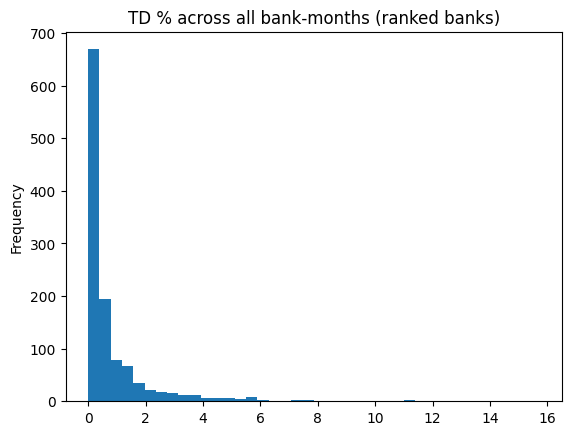

In [5]:
ranked = df[df.is_ranked == 1]
ranked.td_pct.plot(kind='hist', bins=40, title='TD % across all bank-months (ranked banks)')

print('bank-months with TD above 1%:', (ranked.td_pct > 1).sum(), 'of', len(ranked))
ranked.nlargest(10, 'td_pct')[['month', 'bank_name', 'volume_mn', 'td_pct']]